In [29]:
from tensorflow import keras
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [7]:
data = datasets.load_iris()

In [8]:
df = pd.DataFrame(data.data, columns = data.feature_names)

In [9]:
df["species"] = data.target

In [10]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [12]:
df.shape

(150, 5)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int32  
dtypes: float64(4), int32(1)
memory usage: 5.4 KB


In [14]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [15]:
df["species"].value_counts()

species
0    50
1    50
2    50
Name: count, dtype: int64

In [16]:
x = df.drop("species", axis = 1)
y = df["species"]

In [17]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y,
                                                    random_state = 26)

In [24]:
x_sub, x_val, y_sub, y_val = train_test_split(x_train, y_train, test_size = 0.2,
                                              stratify = y_train, random_state = 26)

In [25]:
x_train.shape, x_test.shape

((120, 4), (30, 4))

In [26]:
x_sub.shape, x_val.shape

((96, 4), (24, 4))

In [19]:
model = keras.Sequential()

In [20]:
# 입력층
model.add(keras.Input(shape = (4,)))

# 은닉층
model.add(keras.layers.Dense(16, activation = "relu"))

# 출력층
model.add(keras.layers.Dense(3, activation = "softmax"))

In [21]:
model.compile(loss = "sparse_categorical_crossentropy", optimizer = "adam", metrics = ["accuracy"])

In [27]:
history = model.fit(x_sub, y_sub, batch_size = 8, validation_data = (x_val, y_val), epochs = 100)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3569 - loss: 3.2279 - val_accuracy: 0.3333 - val_loss: 2.9288
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3747 - loss: 2.8447 - val_accuracy: 0.3333 - val_loss: 2.5937
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3608 - loss: 2.2780 - val_accuracy: 0.3333 - val_loss: 2.3484
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3070 - loss: 2.4431 - val_accuracy: 0.3333 - val_loss: 2.1740
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3371 - loss: 2.0771 - val_accuracy: 0.2083 - val_loss: 2.0411
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3075 - loss: 1.8922 - val_accuracy: 0.2917 - val_loss: 1.9196
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2540 - loss: 1.8220 - val_accuracy: 0.2917 - val_loss: 1.8096
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2113 - loss: 1.7742 - val_accuracy: 0.2917 -

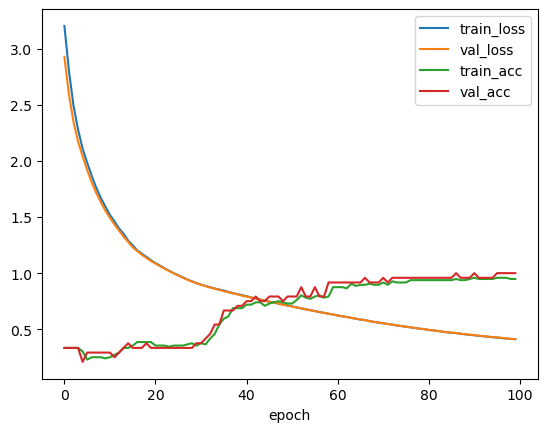

In [30]:
plt.figure()

plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()

plt.show()

In [31]:
model.evaluate(x_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9333 - loss: 0.4407


[0.4407077133655548, 0.9333333373069763]

# ver2

- to_categorical()

In [41]:
enc_y_sub = keras.utils.to_categorical(y_sub)

In [42]:
enc_y_sub[:5]

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [1., 0., 0.]])

In [43]:
y_sub[:5]

7      0
71     1
104    2
121    2
18     0
Name: species, dtype: int32

In [37]:
enc_y_val = keras.utils.to_categorical(y_val)
enc_y_test = keras.utils.to_categorical(y_test)

In [44]:
model2 = keras.Sequential()
model2.add(keras.Input(shape = (4,)))
model2.add(keras.layers.Dense(16, activation = "relu"))
model2.add(keras.layers.Dense(3, activation = "softmax"))

In [45]:
model2.compile(loss = "categorical_crossentropy", optimizer = "adam", metrics = ["accuracy"])

In [46]:
model2.fit(x_sub, enc_y_sub, epochs = 100, batch_size = 8, validation_data = (x_val, enc_y_val))

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.2888 - loss: 1.9006 - val_accuracy: 0.3333 - val_loss: 1.4013
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3530 - loss: 1.3030 - val_accuracy: 0.3750 - val_loss: 1.1941
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3451 - loss: 1.1590 - val_accuracy: 0.3333 - val_loss: 1.1110
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2596 - loss: 1.1093 - val_accuracy: 0.1667 - val_loss: 1.0807
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2280 - loss: 1.0749 - val_accuracy: 0.2917 - val_loss: 1.0529
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2233 - loss: 1.0547 - val_accuracy: 0.1667 - val_loss: 1.0201
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2638 - loss: 1.0185 - val_accuracy: 0.2500 - val_loss: 0.9913
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2338 - loss: 0.9936 - val_accuracy: 0.3333 -

In [47]:
model2.evaluate(x_test, enc_y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 1.0000 - loss: 0.2941


[0.29410749673843384, 1.0]